In [9]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder,StandardScaler

In [10]:
df = pd.read_csv("..\\data\\Breast_cancer_dataset.csv")

target = df.iloc[:,1].values
features = df.iloc[:,2:-1].values

from sklearn.preprocessing import StandardScaler,LabelEncoder

le = LabelEncoder()
ss = StandardScaler()

target = le.fit_transform(target).reshape(-1,1)
features = ss.fit_transform(features)

x_train = features[:400]
y_train = target[:400]
x_test = features[400:]
y_test = target[400:]

In [11]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
model.fit(x_train,y_train)

C:\Users\JATIN\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,priors,None
,var_smoothing,1e-09


In [12]:
y_pred = model.predict(x_test)

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,auc,roc_auc_score,roc_curve
def statistical_outcomes(x,y):
    mat = confusion_matrix(x,y)
    acc = accuracy_score(x,y)
    pre = precision_score(x,y)
    rec = recall_score(x,y)
    f1s = f1_score(x,y)
    _roc = roc_auc_score(x,y)
    print("Confusion matrix: \n",mat)
    print("Accuracy Score: \n",acc)
    print("Precision Score: \n",pre)
    print("Recall Score: \n",rec)
    print("F1 Score: \n",f1s)
    print("ROC_AUC Score: \n",_roc)
    p,q,r = roc_curve(y_test,y_pred)
    plt.plot(p,q)
    plt.xlabel("fpr")
    plt.ylabel("tpr")
    plt.title("Roc_curve")
    plt.show()


Confusion matrix: 
 [[122   3]
 [  8  36]]
Accuracy Score: 
 0.9349112426035503
Precision Score: 
 0.9230769230769231
Recall Score: 
 0.8181818181818182
F1 Score: 
 0.8674698795180723
ROC_AUC Score: 
 0.8970909090909092


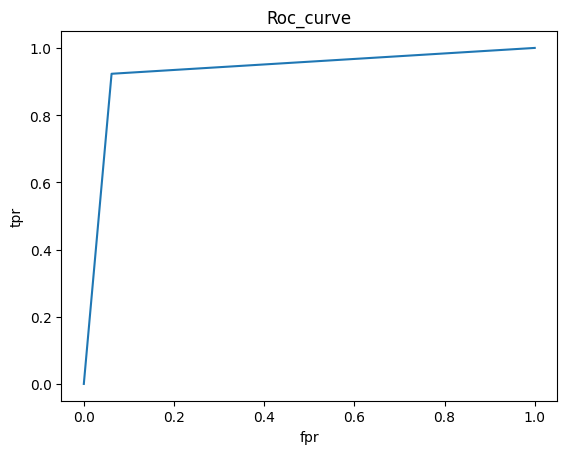

In [14]:
statistical_outcomes(y_pred,y_test)